# Sprint 6 — Análise de vendas de jogos da loja Ice

Eu analisei dados de videogames para identificar padrões associados às vendas e orientar campanhas para 2017, considerando o cenário de dezembro de 2016.

Eu organizei o projeto em abertura dos dados, preparação, análise exploratória, perfil regional, testes de hipóteses e conclusão.

Cada registro representa um jogo em uma plataforma. O mesmo título pode aparecer várias vezes. Eu usei vendas em milhões de USD conforme o enunciado. O ano é o de lançamento: as vendas não representam necessariamente transações realizadas naquele ano.

## Como executar

Eu organizei o projeto para usar `data/games.csv`. Para reproduzir a análise, coloque o CSV nessa pasta, selecione o ambiente Python no VS Code e execute as células na ordem. Na plataforma do curso, altere somente o caminho de leitura para `/datasets/games.csv`.

## 1. Abertura dos dados

Eu usei pandas para analisar tabelas, matplotlib para gráficos e scipy para testes estatísticos.

In [1]:
import pandas as pd  # Eu importei o pandas para trabalhar com tabelas.
import matplotlib.pyplot as plt  # Eu importei o matplotlib para construir gráficos.
from scipy import stats  # Eu importei as ferramentas dos testes estatísticos.

df = pd.read_csv('data/games.csv')  # Eu abri o CSV localizado na pasta data deste projeto.
display(df.head(10))  # Eu mostrei os dez primeiros registros.
print('Linhas e colunas:', df.shape)  # Eu consultei o tamanho da tabela.
df.info()  # Eu consultei os tipos de dados e a quantidade de informações preenchidas.
display(df.isna().sum())  # Eu contei os valores ausentes em cada coluna.
print('Duplicatas completas:', df.duplicated().sum())  # Eu contei registros iguais em todas as colunas.
display(df.describe())  # Eu consultei as estatísticas das colunas numéricas.

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,Tetris,GB,1989.0,Puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
6,New Super Mario Bros.,DS,2006.0,Platform,11.28,9.14,6.50,2.88,89.0,8.5,E
7,Wii Play,Wii,2006.0,Misc,13.96,9.18,2.93,2.84,58.0,6.6,E
8,New Super Mario Bros. Wii,Wii,2009.0,Platform,14.44,6.94,4.70,2.24,87.0,8.4,E
9,Duck Hunt,NES,1984.0,Shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN


Linhas e colunas: (16715, 11)
<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 1.4 MB


Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

Duplicatas completas: 0


,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


### Observações iniciais

Eu encontrei 16.715 registros e 11 colunas. Faltam 2 nomes, 269 anos, 2 gêneros, 8.578 notas críticas, 6.701 notas de usuários e 6.766 classificações ESRB. As vendas regionais estão preenchidas.

Eu identifiquei que os anos estão como decimais e que as notas de usuários contêm texto. Um título em plataformas diferentes não é, por si só, uma duplicata.

## 2. Preparação dos dados

Eu padronizei as colunas em minúsculas e converti o ano para `Int64`, um inteiro que aceita valores ausentes. Eu converti a nota dos usuários para número e tratei `tbd` (nota ainda não determinada) como ausente, nunca como zero.

Eu removi os dois registros sem nome ou gênero, mantive anos e notas desconhecidos sem inventar valores e identifiquei classificações ausentes como “Não informado”. Os anos desconhecidos ficam fora das análises temporais; notas ausentes ficam fora apenas das análises que precisam delas.

Falhas de cadastro ou coleta e avaliações não disponíveis são possíveis causas das ausências, mas eu não consigo confirmar cada motivo com a base. Classificação ausente não significa conteúdo adequado a todas as idades.

In [2]:
df.columns = df.columns.str.lower()  # Eu transformei os nomes das colunas em letras minúsculas.
print('Notas tbd:', (df['user_score'] == 'tbd').sum())  # Eu contei as notas ainda não determinadas.
display(df[df['name'].isna() | df['genre'].isna()])  # Eu inspecionei os registros sem nome ou gênero.
df = df.drop_duplicates().copy()  # Eu removi possíveis duplicatas completas.
df = df.dropna(subset=['name', 'genre']).copy()  # Eu removi os registros sem identificação ou gênero.
df['year_of_release'] = df['year_of_release'].astype('Int64')  # Eu converti os anos para inteiros mantendo ausências.
df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce')  # Eu converti notas para números e textos como tbd para ausências.
df['rating'] = df['rating'].fillna('Não informado')  # Eu preservei os registros sem classificação com uma categoria própria.
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']  # Eu somei as vendas das quatro regiões.
display(df.dtypes)  # Eu conferi os tipos depois das alterações.
display(df.isna().sum())  # Eu conferi as ausências restantes.
display(df.head())  # Eu conferi a tabela preparada.

Notas tbd: 2424


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,NaN,GEN,1993.0,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993.0,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN


name                   str
platform               str
year_of_release      Int64
genre                  str
na_sales           float64
eu_sales           float64
jp_sales           float64
other_sales        float64
critic_score       float64
user_score         float64
rating                 str
total_sales        float64
dtype: object

name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating                0
total_sales           0
dtype: int64

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,Não informado,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,Não informado,31.38


## 3. Análise exploratória

### 3.1. Lançamentos por ano

Eu contei registros de lançamentos por plataforma, e não títulos únicos. Anos ausentes não entram no agrupamento.

year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64

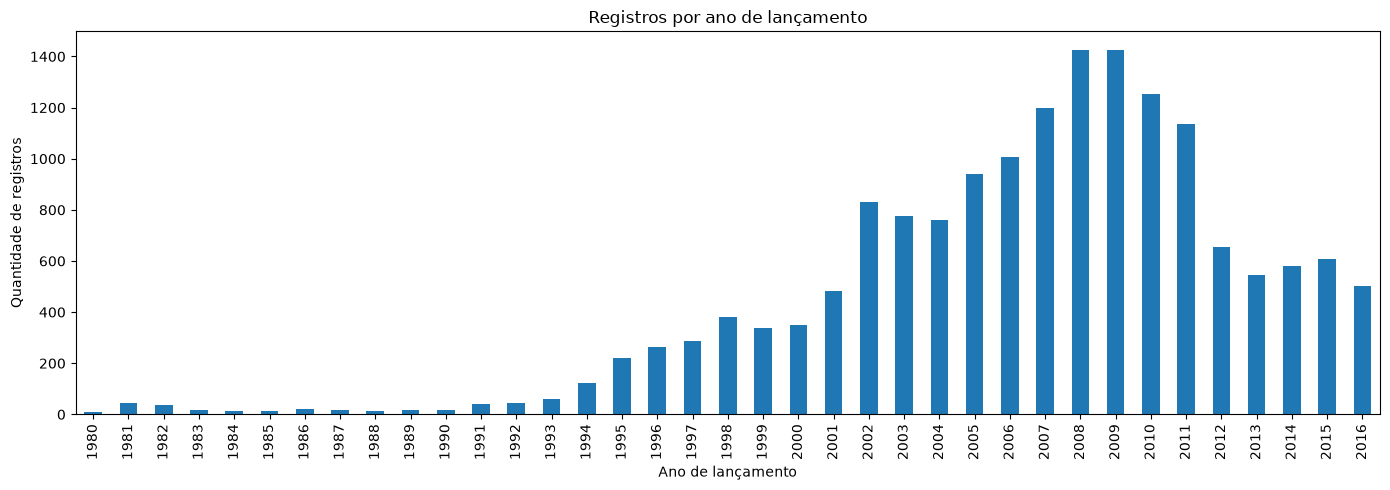

In [3]:
jogos_por_ano = df.groupby('year_of_release')['name'].count()  # Eu contei os registros por ano.
display(jogos_por_ano)  # Eu mostrei a contagem anual.
jogos_por_ano.plot(kind='bar', figsize=(14, 5))  # Eu construí o gráfico de barras.
plt.title('Registros por ano de lançamento')  # Eu defini o título.
plt.xlabel('Ano de lançamento')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Quantidade de registros')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços do gráfico.
plt.show()  # Eu exibi o gráfico.

Eu observei poucos registros nos primeiros anos e maior volume em 2008 e 2009. Os anos antigos representam outras gerações de plataformas e são menos relevantes para planejar 2017. Essa avaliação é sobre cobertura e relevância, não significância estatística. A redução em 2016 pode refletir a possível incompletude do ano.

### 3.2. Histórico das plataformas

Eu selecionei as seis plataformas com maiores vendas acumuladas e examinei a distribuição por ano de lançamento.

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
3DS      259.00
XB       257.74
GB       255.46
NES      251.05
N64      218.68
SNES     200.04
GC       198.93
XOne     159.32
2600      96.98
WiiU      82.19
PSV       54.07
SAT       33.59
GEN       28.35
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: total_sales, dtype: float64

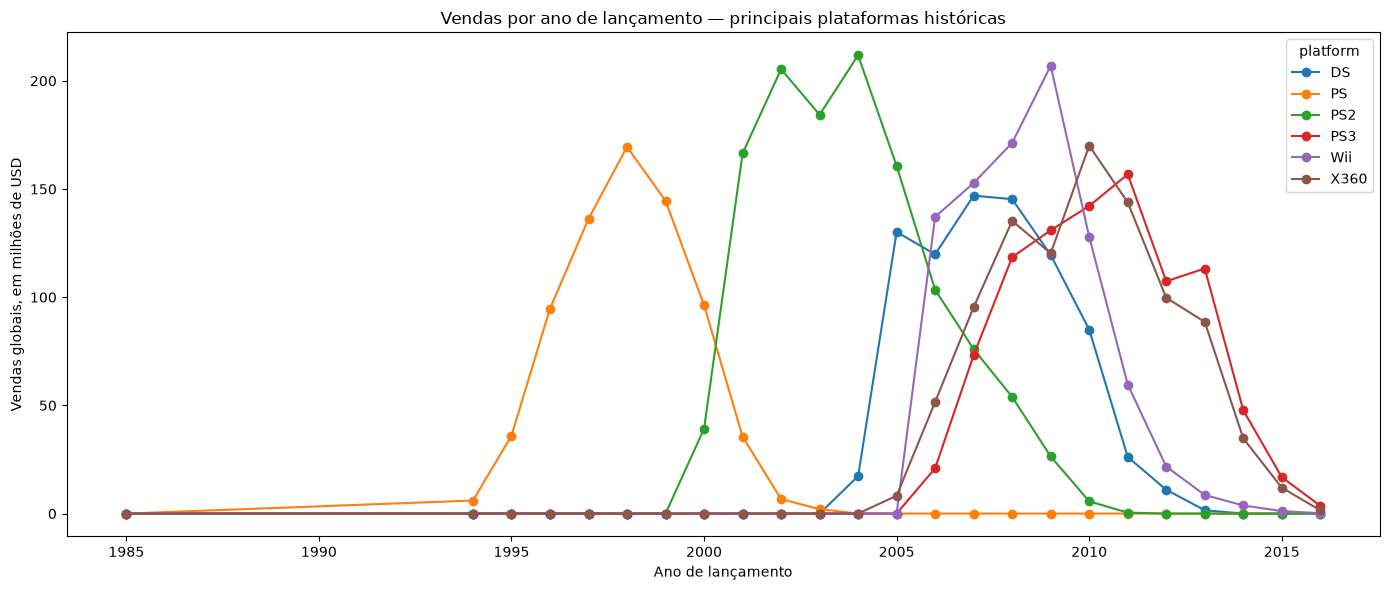

,min,max,intervalo_observado
platform,,,
2600,1980,1989,10
NES,1983,1994,12
PC,1985,2016,32
DS,1985,2013,29
GB,1988,2001,14
GEN,1990,1994,5
SNES,1990,1999,10
GG,1992,1992,1
SCD,1993,1994,2


In [4]:
vendas_plataformas = df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)  # Eu calculei o ranking histórico de vendas.
top6 = vendas_plataformas.head(6).index.tolist()  # Eu selecionei os nomes das seis líderes.
df_top6 = df[df['platform'].isin(top6)]  # Eu selecionei os registros dessas plataformas.
historico = df_top6.pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum', fill_value=0)  # Eu organizei as vendas por ano e plataforma.
display(vendas_plataformas)  # Eu mostrei o ranking histórico.
historico.plot(figsize=(14, 6), marker='o')  # Eu construí as linhas das plataformas.
plt.title('Vendas por ano de lançamento — principais plataformas históricas')  # Eu defini o título.
plt.xlabel('Ano de lançamento')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas globais, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.
periodos = df.groupby('platform')['year_of_release'].agg(['min', 'max'])  # Eu identifiquei o primeiro e o último ano de cada plataforma.
periodos['intervalo_observado'] = periodos['max'] - periodos['min'] + 1  # Eu calculei o intervalo incluindo os dois extremos.
display(periodos.sort_values('min'))  # Eu mostrei os intervalos observados.

Eu identifiquei PS2, X360, PS3, Wii, DS e PS como líderes históricas. Eu observei crescimento, pico e redução nas vendas de seus lançamentos. PS e PS2 deixam de apresentar lançamentos nos anos recentes.

Eu considerei aproximadamente uma década como referência geral de substituição de gerações, com sobreposição entre antigas e novas, sem tratar esse prazo como regra. O intervalo calculado não é a vida útil oficial do console. Plataformas ainda ativas têm seu histórico limitado ao fim da base.

O DS apresenta um registro muito antigo que pode alongar seu intervalo; eu não corrigi o ano sem informação confirmatória. A ausência de lançamentos recentes não prova que jogos antigos deixaram de vender.

### 3.3. Período relevante

Eu escolhi 2013–2016, que inclui a entrada de PS4 e Xbox One e a transição entre gerações. Daqui em diante, eu utilizei somente esse recorte. Eu dei mais atenção a 2014–2015 para avaliar crescimento, pois 2016 pode estar incompleto.

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

platform,3DS,DS,PC,PS3,PS4,PSP,PSV,Wii,WiiU,X360,XOne
year_of_release,,,,,,,,,,,
2013,56.57,1.54,12.38,113.25,25.99,3.14,10.59,8.59,21.65,88.58,18.96
2014,43.76,0.00,13.28,47.76,100.00,0.24,11.90,3.75,22.03,34.74,54.07
2015,27.78,0.00,8.52,16.82,118.90,0.12,6.25,1.14,16.35,11.96,60.14
2016,15.14,0.00,5.25,3.60,69.25,0.00,4.25,0.18,4.60,1.52,26.15


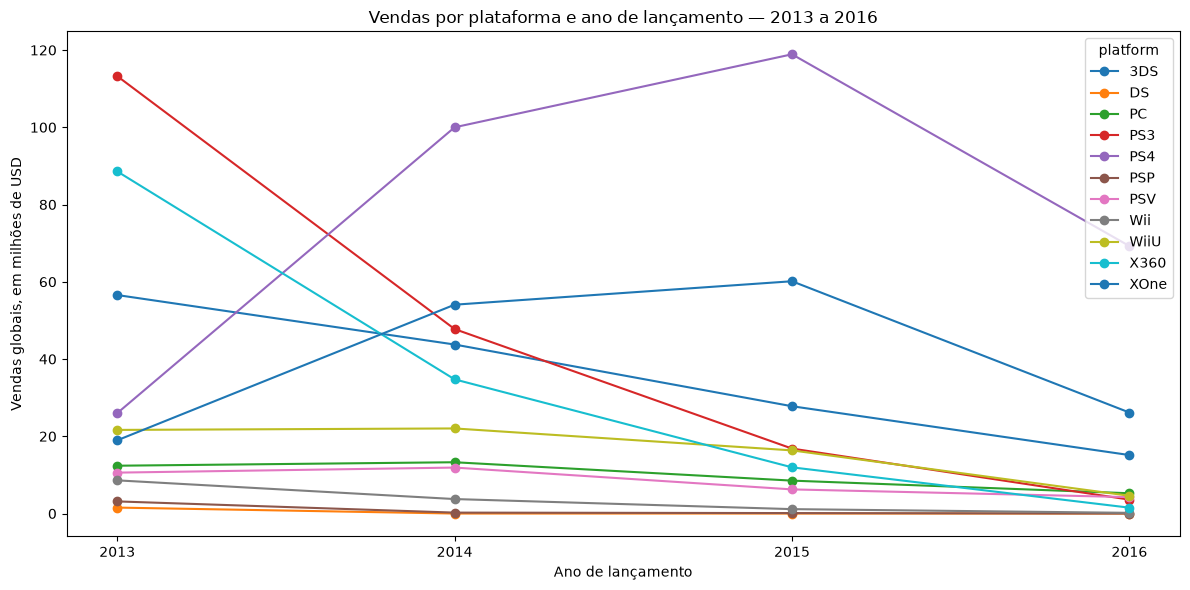

In [5]:
df_atual = df[(df['year_of_release'] >= 2013) & (df['year_of_release'] <= 2016)].copy()  # Eu selecionei o período de 2013 a 2016.
lideres = df_atual.groupby('platform')['total_sales'].sum().sort_values(ascending=False)  # Eu calculei o ranking recente.
vendas_anuais = df_atual.pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum', fill_value=0)  # Eu organizei as vendas recentes por ano e plataforma.
display(lideres)  # Eu mostrei as vendas acumuladas.
display(vendas_anuais)  # Eu mostrei os valores anuais.
vendas_anuais.plot(figsize=(12, 6), marker='o')  # Eu construí o gráfico das trajetórias recentes.
plt.title('Vendas por plataforma e ano de lançamento — 2013 a 2016')  # Eu defini o título.
plt.xlabel('Ano de lançamento')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas globais, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.xticks([2013, 2014, 2015, 2016])  # Eu mostrei somente os anos do recorte.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.

### Plataformas com potencial comercial

Eu identifiquei PS4 como líder acumulada e crescimento de PS4 e Xbox One entre 2014 e 2015. Eu priorizaria essas duas plataformas para avaliar campanhas de 2017.

PS3 e X360 apresentam redução, apesar do acumulado relevante. Eu consideraria 3DS para campanhas regionais, especialmente no Japão, ponderando sua trajetória de queda.

Eu não usei a redução de 2016 isoladamente para descartar plataformas: o ano pode estar incompleto e jogos recentes tiveram menos tempo para vender. Eu avaliei potencial comercial, e não lucro, pois faltam custos e margens.

### 3.4. Distribuição das vendas por plataforma

Eu comparei médias, medianas, desvio padrão e variância. No boxplot, a linha central é a mediana e a caixa contém os 50% centrais. Eu mostrei uma versão completa e outra com escala reduzida, sem retirar registros dos cálculos.

,count,mean,median,std,var
platform,,,,,
PS4,392,0.801378,0.200,1.609456,2.590350
X360,186,0.735484,0.265,1.663275,2.766484
XOne,247,0.645020,0.220,1.036139,1.073584
Wii,23,0.593913,0.180,0.915432,0.838016
WiiU,115,0.562000,0.200,1.038778,1.079060
PS3,345,0.525884,0.150,1.451939,2.108128
3DS,303,0.472772,0.090,1.381347,1.908119
PC,189,0.208624,0.080,0.352304,0.124118
DS,8,0.192500,0.150,0.172026,0.029593


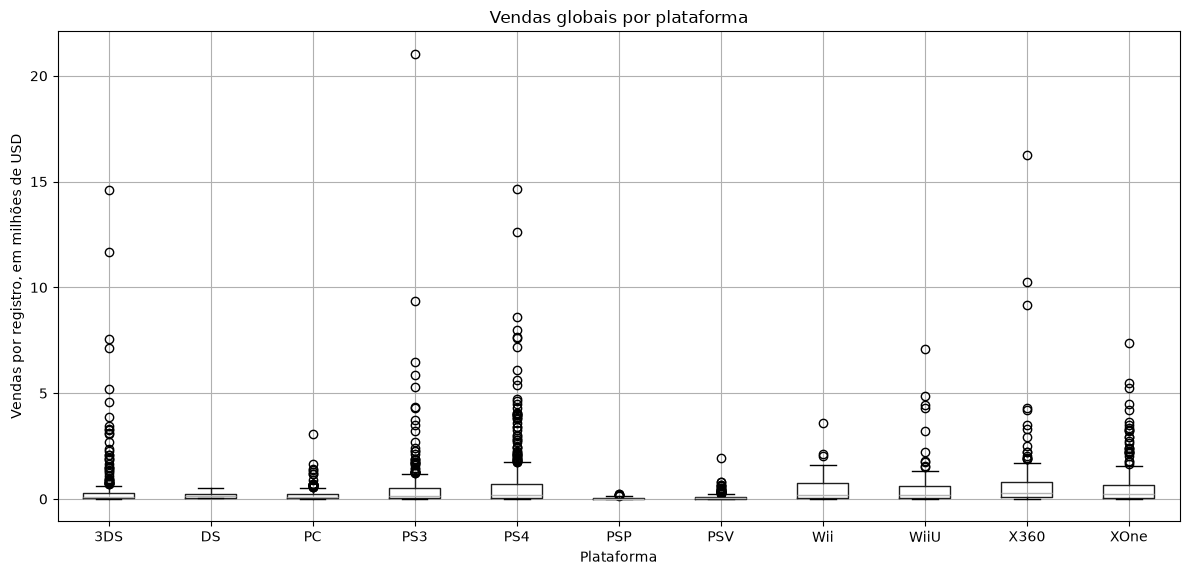

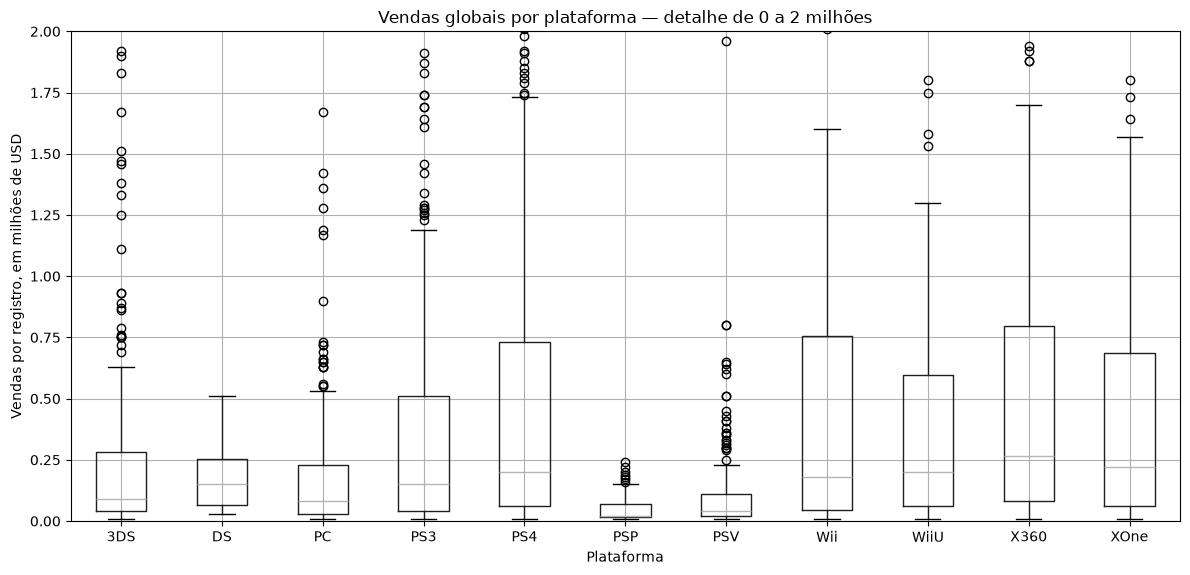

In [6]:
resumo = df_atual.groupby('platform')['total_sales'].agg(['count', 'mean', 'median', 'std', 'var'])  # Eu calculei as medidas de distribuição das vendas.
display(resumo.sort_values('mean', ascending=False))  # Eu organizei os resultados pela média.
df_atual.boxplot(column='total_sales', by='platform', figsize=(12, 6))  # Eu construí o boxplot completo.
plt.title('Vendas globais por plataforma')  # Eu defini o título.
plt.suptitle('')  # Eu retirei o título adicional automático.
plt.xlabel('Plataforma')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas por registro, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.
df_atual.boxplot(column='total_sales', by='platform', figsize=(12, 6))  # Eu reconstruí o boxplot para examinar as caixas.
plt.ylim(0, 2)  # Eu limitei somente a visualização ao intervalo entre zero e dois milhões.
plt.title('Vendas globais por plataforma — detalhe de 0 a 2 milhões')  # Eu indiquei a escala reduzida.
plt.suptitle('')  # Eu retirei o título adicional automático.
plt.xlabel('Plataforma')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas por registro, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.

Eu observei poucos sucessos muito acima da maioria, elevando as médias. Eu usei a mediana para avaliar um registro típico. PS4, XOne e X360 têm médias superiores à de PC, mas existe sobreposição entre distribuições.

Eu identifiquei diferenças descritivas, sem afirmar significância estatística apenas pelo boxplot. O desvio padrão mede dispersão em torno da média e a variância fica na unidade ao quadrado. Eu usei o cálculo amostral padrão do pandas, com divisor n−1. Total alto e média alta representam perguntas diferentes.

### 3.5. Avaliações e vendas do PS4

Eu escolhi a plataforma líder recente. Eu calculei correlação de Pearson separadamente para notas críticas e de usuários, usando apenas notas preenchidas. A correlação mede associação linear de −1 a 1 e não demonstra causalidade.

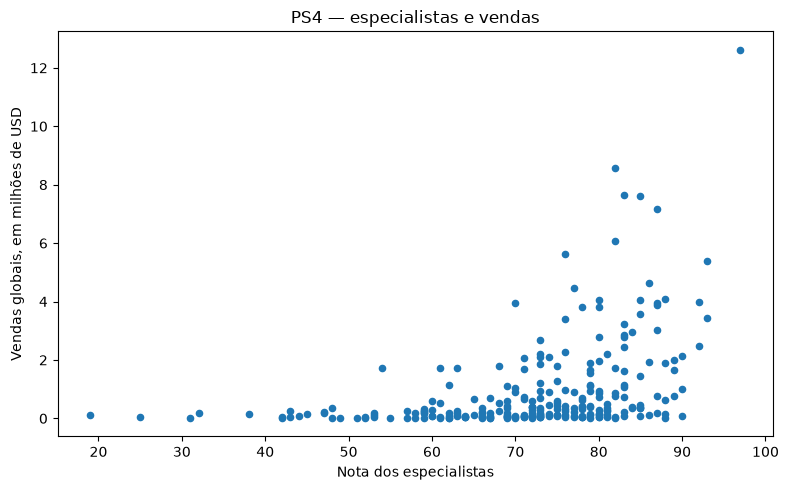

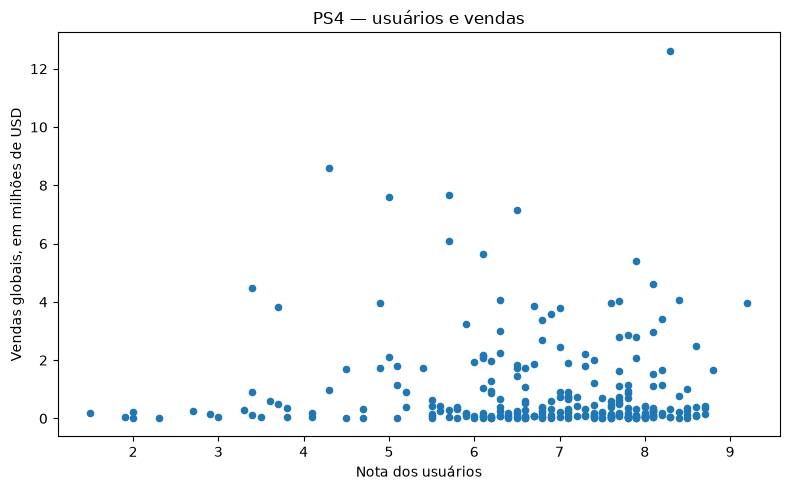

Correlação crítica: 0.4065679020617816
Correlação usuários: -0.03195711020455643


In [7]:
df_ps4 = df_atual[df_atual['platform'] == 'PS4'].copy()  # Eu selecionei os registros de PS4.
ps4_critica = df_ps4.dropna(subset=['critic_score'])  # Eu mantive os registros com nota crítica.
ps4_usuario = df_ps4.dropna(subset=['user_score'])  # Eu mantive os registros com nota de usuário.
ps4_critica.plot(kind='scatter', x='critic_score', y='total_sales', figsize=(8, 5))  # Eu comparei notas críticas e vendas.
plt.title('PS4 — especialistas e vendas')  # Eu defini o título.
plt.xlabel('Nota dos especialistas')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas globais, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.
ps4_usuario.plot(kind='scatter', x='user_score', y='total_sales', figsize=(8, 5))  # Eu comparei notas de usuários e vendas.
plt.title('PS4 — usuários e vendas')  # Eu defini o título.
plt.xlabel('Nota dos usuários')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas globais, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.
print('Correlação crítica:', ps4_critica['critic_score'].corr(ps4_critica['total_sales']))  # Eu calculei a associação linear entre notas críticas e vendas.
print('Correlação usuários:', ps4_usuario['user_score'].corr(ps4_usuario['total_sales']))  # Eu calculei a associação linear entre notas de usuários e vendas.

Eu encontrei associação positiva moderada entre notas críticas e vendas de PS4 e correlação linear próxima de zero para notas de usuários. Eu usaria notas críticas como informação complementar, sem concluir que causam vendas maiores. Divulgação e popularidade podem influenciar ambas; a ausência de notas também pode selecionar o catálogo analisado.

### 3.6. Os mesmos títulos em outras plataformas

Eu comparei cinco sucessos multiplataforma e, depois, todos os títulos compartilhados entre PS4 e XOne. A primeira seleção representa grandes sucessos, não todo o catálogo.

In [8]:
quantidade_plataformas = df_atual.groupby('name')['platform'].nunique()  # Eu contei as plataformas de cada título.
nomes_multi = quantidade_plataformas[quantidade_plataformas > 1].index  # Eu selecionei títulos presentes em mais de uma plataforma.
jogos_multi = df_atual[df_atual['name'].isin(nomes_multi)]  # Eu selecionei os registros desses títulos.
top5_multi = jogos_multi.groupby('name')['total_sales'].sum().sort_values(ascending=False).head(5)  # Eu identifiquei cinco grandes sucessos multiplataforma.
dados_top5 = df_atual[df_atual['name'].isin(top5_multi.index)]  # Eu selecionei seus registros.
comparacao = dados_top5.pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum')  # Eu organizei as vendas por título e plataforma.
display(comparacao)  # Eu mostrei as diferenças dos mesmos títulos.
vendas_titulos = df_atual.pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum')  # Eu organizei todos os títulos por plataforma.
compartilhados = vendas_titulos[['PS4', 'XOne']].dropna()  # Eu mantive títulos registrados nas duas plataformas.
print('Títulos compartilhados:', len(compartilhados))  # Eu mostrei o tamanho da comparação.
display(compartilhados.agg(['sum', 'mean', 'median']))  # Eu comparei o mesmo conjunto de títulos.
for plataforma in ['XOne', 'PS3', 'PC']:  # Eu repeti a análise de correlação em outras plataformas.
    dados_plataforma = df_atual[df_atual['platform'] == plataforma]  # Eu selecionei o catálogo da plataforma.
    print('\nPlataforma:', plataforma)  # Eu identifiquei o resultado apresentado.
    print('Crítica e vendas:', dados_plataforma['critic_score'].corr(dados_plataforma['total_sales']))  # Eu calculei a correlação com notas críticas preenchidas.
    print('Usuários e vendas:', dados_plataforma['user_score'].corr(dados_plataforma['total_sales']))  # Eu calculei a correlação com notas de usuários preenchidas.

platform,PC,PS3,PS4,PSV,WiiU,X360,XOne
name,,,,,,,
Call of Duty: Advanced Warfare,0.41,4.36,7.66,NaN,NaN,4.28,5.26
Call of Duty: Black Ops 3,0.26,1.69,14.63,NaN,NaN,1.70,7.39
Call of Duty: Ghosts,0.69,9.36,3.83,NaN,0.35,10.24,2.92
Grand Theft Auto V,1.17,21.05,12.62,NaN,NaN,16.27,5.47
Minecraft,NaN,5.27,4.32,1.96,0.67,9.18,2.76


Títulos compartilhados: 217


platform,PS4,XOne
sum,256.350000,129.360000
mean,1.181336,0.596129
median,0.420000,0.210000



Plataforma: XOne
Crítica e vendas: 0.4169983280084017
Usuários e vendas: -0.06892505328279416

Plataforma: PS3
Crítica e vendas: 0.3342853393371919
Usuários e vendas: 0.0023944027357566907

Plataforma: PC
Crítica e vendas: 0.1960302829436937
Usuários e vendas: -0.09384186952476749


Eu observei vendas diferentes para o mesmo título. GTA V tem vendas maiores em PS3 e X360; no conjunto compartilhado entre PS4 e XOne, PS4 apresenta média maior. Eu não medi o efeito de público ou tempo de exposição, portanto não atribuí causalidade a esses fatores.

Eu observei associação positiva com notas críticas em outras plataformas, com intensidades diferentes, e ausência de um padrão forte uniforme para usuários. Essas correlações usam o catálogo de cada plataforma, não apenas títulos compartilhados. A identificação por nome não controla todas as diferenças entre edições.

### 3.7. Gêneros

Eu comparei quantidade de registros, total, média e mediana para separar volume do catálogo de desempenho por registro.

,count,sum,mean,median
genre,,,,
Action,766,321.87,0.420196,0.110
Shooter,187,232.98,1.245882,0.450
Sports,214,150.65,0.703972,0.240
Role-Playing,292,145.89,0.499623,0.125
Misc,155,62.82,0.405290,0.100
Platform,74,42.63,0.576081,0.225
Racing,85,39.89,0.469294,0.120
Fighting,80,35.31,0.441375,0.125
Adventure,245,23.64,0.096490,0.030


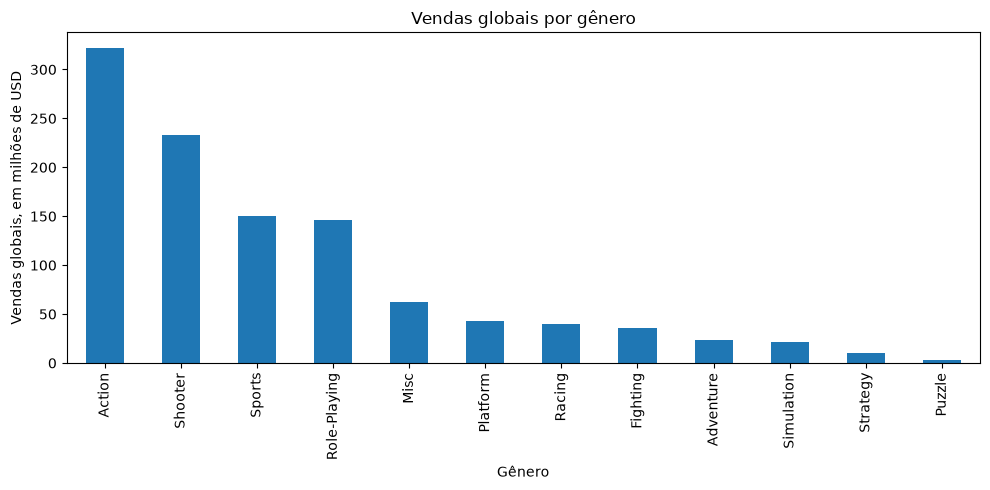

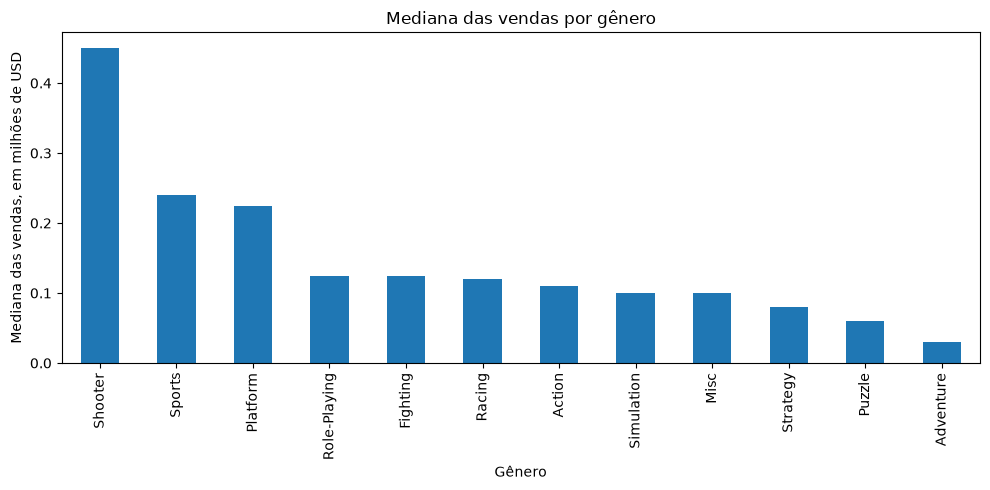

In [9]:
generos = df_atual.groupby('genre')['total_sales'].agg(['count', 'sum', 'mean', 'median']).sort_values('sum', ascending=False)  # Eu calculei os indicadores por gênero.
display(generos)  # Eu mostrei a tabela comparativa.
generos['sum'].plot(kind='bar', figsize=(10, 5))  # Eu comparei as vendas totais por gênero.
plt.title('Vendas globais por gênero')  # Eu defini o título.
plt.xlabel('Gênero')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Vendas globais, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.
generos['median'].sort_values(ascending=False).plot(kind='bar', figsize=(10, 5))  # Eu comparei medianas por gênero.
plt.title('Mediana das vendas por gênero')  # Eu defini o título.
plt.xlabel('Gênero')  # Eu identifiquei o eixo horizontal.
plt.ylabel('Mediana das vendas, em milhões de USD')  # Eu identifiquei o eixo vertical.
plt.tight_layout()  # Eu ajustei os espaços.
plt.show()  # Eu exibi o gráfico.

Eu identifiquei Action como líder total, com muitos registros, e Shooter como destaque em média e mediana. Sports também é comercialmente relevante. Adventure, Puzzle e Strategy têm volumes menores. Eu não generalizei que todo jogo desses gêneros venderá pouco e não calculei lucro sem custos e margens.

## 4. Perfil regional

Eu comparei as cinco principais plataformas, os cinco gêneros e as classificações ESRB por região. Eu usei todas as vendas da região como denominador das participações, não somente o top 5. Os percentuais descrevem a base de 2013–2016, não todo o mercado.

In [10]:
regioes = ['na_sales', 'eu_sales', 'jp_sales']  # Eu listei as colunas regionais.
nomes_regioes = ['América do Norte', 'Europa', 'Japão']  # Eu listei seus nomes na mesma ordem.
for i in range(len(regioes)):  # Eu repeti a comparação de plataformas para cada região.
    coluna = regioes[i]  # Eu selecionei a coluna regional.
    total = df_atual[coluna].sum()  # Eu calculei todas as vendas da região.
    top5 = df_atual.groupby('platform')[coluna].sum().sort_values(ascending=False).head(5)  # Eu selecionei as cinco plataformas líderes.
    perfil = top5.to_frame(name='vendas_milhoes')  # Eu transformei os resultados em tabela.
    perfil['participacao_percentual'] = perfil['vendas_milhoes'] / total * 100  # Eu calculei a participação no total regional.
    print('\nPlataformas —', nomes_regioes[i])  # Eu identifiquei a região.
    display(perfil)  # Eu mostrei a tabela.


Plataformas — América do Norte


,vendas_milhoes,participacao_percentual
platform,,
PS4,108.74,24.842933
XOne,93.12,21.274360
X360,81.66,18.656188
PS3,63.50,14.507322
3DS,38.20,8.727239



Plataformas — Europa


,vendas_milhoes,participacao_percentual
platform,,
PS4,141.09,35.971241
PS3,67.81,17.288326
XOne,51.59,13.152997
X360,42.52,10.840578
3DS,30.96,7.893328



Plataformas — Japão


,vendas_milhoes,participacao_percentual
platform,,
3DS,67.81,48.167353
PS3,23.35,16.586163
PSV,18.59,13.205001
PS4,15.96,11.336838
WiiU,10.88,7.728371


In [11]:
for i in range(len(regioes)):  # Eu repeti a comparação de gêneros para cada região.
    coluna = regioes[i]  # Eu selecionei a coluna regional.
    total = df_atual[coluna].sum()  # Eu calculei todas as vendas da região.
    top5 = df_atual.groupby('genre')[coluna].sum().sort_values(ascending=False).head(5)  # Eu selecionei os cinco gêneros líderes.
    perfil = top5.to_frame(name='vendas_milhoes')  # Eu transformei os resultados em tabela.
    perfil['participacao_percentual'] = perfil['vendas_milhoes'] / total * 100  # Eu calculei a participação regional.
    print('\nGêneros —', nomes_regioes[i])  # Eu identifiquei a região.
    display(perfil)  # Eu mostrei a tabela.


Gêneros — América do Norte


,vendas_milhoes,participacao_percentual
genre,,
Action,126.05,28.797606
Shooter,109.74,25.071394
Sports,65.27,14.911700
Role-Playing,46.40,10.600626
Misc,27.49,6.280414



Gêneros — Europa


,vendas_milhoes,participacao_percentual
genre,,
Action,118.13,30.117533
Shooter,87.86,22.400122
Sports,60.52,15.429722
Role-Playing,36.97,9.425592
Racing,20.19,5.147490



Gêneros — Japão


,vendas_milhoes,participacao_percentual
genre,,
Role-Playing,51.04,36.255150
Action,40.49,28.761188
Misc,9.20,6.535019
Fighting,7.65,5.434011
Shooter,6.61,4.695269


In [12]:
for i in range(len(regioes)):  # Eu repeti a análise de ESRB para cada região.
    coluna = regioes[i]  # Eu selecionei a coluna regional.
    total = df_atual[coluna].sum()  # Eu calculei todas as vendas da região.
    perfil = df_atual.groupby('rating')[coluna].agg(['sum', 'mean', 'median']).sort_values('sum', ascending=False)  # Eu comparei total, média e mediana por classificação.
    perfil['participacao_percentual'] = perfil['sum'] / total * 100  # Eu calculei a participação regional.
    print('\nESRB —', nomes_regioes[i])  # Eu identifiquei a região.
    display(perfil)  # Eu mostrei a tabela.


ESRB — América do Norte


,sum,mean,median,participacao_percentual
rating,,,,
M,165.21,0.447724,0.14,37.744169
Não informado,89.42,0.091525,0.00,20.429051
E,79.05,0.261755,0.05,18.059903
E10+,54.24,0.215238,0.12,12.391766
T,49.79,0.149520,0.04,11.375111



ESRB — Europa


,sum,mean,median,participacao_percentual
rating,,,,
M,145.32,0.393821,0.130,37.049690
E,83.36,0.276026,0.055,21.252836
Não informado,78.91,0.080768,0.000,20.118298
E10+,42.69,0.169405,0.100,10.883920
T,41.95,0.125976,0.040,10.695255



ESRB — Japão


,sum,mean,median,participacao_percentual
rating,,,,
Não informado,85.05,0.087052,0.02,60.413411
T,20.59,0.061832,0.01,14.625657
E,15.14,0.050132,0.00,10.754369
M,14.11,0.038238,0.00,10.022731
E10+,5.89,0.023373,0.00,4.183833


### Interpretação regional

- **América do Norte:** eu identifiquei PS4, XOne, X360, PS3 e 3DS no top 5. Action, Shooter, Sports, Role-Playing e Misc lideram os gêneros. Eu observei participação importante da família Xbox.
- **Europa:** eu identifiquei PS4, PS3, XOne, X360 e 3DS. Action, Shooter, Sports, Role-Playing e Racing lideram. Eu observei maior participação de PS4 do que na América do Norte.
- **Japão:** eu identifiquei 3DS, PS3, PSV, PS4 e WiiU. Role-Playing, Action, Misc, Fighting e Shooter lideram. Eu observei maior presença de portáteis e baixa participação de Xbox.

Eu identifiquei M como líder de vendas na América do Norte e Europa. No Japão, “Não informado” domina; T lidera entre classificações conhecidas. Eu preservei ausências para não esconder esse volume.

Eu não concluí que ESRB causa vendas. As médias consideram registros inclusive com venda zero na região. Eu descrevi vendas, não idade ou características pessoais dos compradores.

## 5. Testes de hipóteses

Eu escolhi o teste t de Welch bilateral, com `equal_var=False`, sem assumir variâncias iguais. Eu defini alfa = 0,05, um limiar convencional que controla em 5% a probabilidade de rejeitar H₀ quando ela é verdadeira, sob as condições do teste.

Eu rejeito H₀ se p < 0,05; caso contrário, eu não rejeito H₀. Não rejeitar não prova igualdade ou equivalência. Eu usei apenas notas preenchidas de 2013–2016.

Eu considerei os registros independentes para aplicar o teste, mas títulos repetidos podem limitar essa suposição. Ausências seletivas e a coleta não aleatória também limitam a generalização.

### Xbox One e PC

**H₀:** as médias das notas de usuários dos dois grupos são iguais.

**H₁:** as médias das notas de usuários dos dois grupos são diferentes.

Eu usei um teste bilateral porque não defini uma direção antecipada para a diferença.

In [13]:
alfa = 0.05  # Eu defini o nível de significância de 5%.
notas_xone = df_atual[df_atual['platform'] == 'XOne']['user_score'].dropna()  # Eu selecionei as notas preenchidas do primeiro grupo.
notas_pc = df_atual[df_atual['platform'] == 'PC']['user_score'].dropna()  # Eu selecionei as notas preenchidas do segundo grupo.
print('XOne:')  # Eu identifiquei o primeiro grupo.
print(notas_xone.agg(['count', 'mean', 'std', 'var']))  # Eu mostrei quantidade, média, desvio padrão e variância amostrais.
print('PC:')  # Eu identifiquei o segundo grupo.
print(notas_pc.agg(['count', 'mean', 'std', 'var']))  # Eu mostrei as mesmas medidas do segundo grupo.
teste_plataformas = stats.ttest_ind(notas_xone, notas_pc, equal_var=False)  # Eu apliquei o teste t de Welch bilateral.
print('Estatística t:', teste_plataformas.statistic)  # Eu mostrei a estatística do teste.
print('P-valor:', teste_plataformas.pvalue)  # Eu mostrei o p-valor.
if teste_plataformas.pvalue < alfa:  # Eu verifiquei se o resultado fica abaixo do limiar.
    print('Eu rejeito H₀: existe evidência de diferença entre as médias.')  # Eu apresentei a decisão significativa.
else:  # Eu defini a alternativa quando o resultado não fica abaixo do limiar.
    print('Eu não rejeito H₀: não encontrei evidência suficiente de diferença entre as médias.')  # Eu apresentei a decisão não significativa.

XOne:
count    182.000000
mean       6.521429
std        1.380941
var        1.906997
Name: user_score, dtype: float64
PC:
count    155.000000
mean       6.269677
std        1.742381
var        3.035893
Name: user_score, dtype: float64
Estatística t: 1.45192815744488
P-valor: 0.1475959401343046
Eu não rejeito H₀: não encontrei evidência suficiente de diferença entre as médias.


Eu obtive p > 0,05 e não rejeitei H₀. Eu não encontrei evidência suficiente de diferença entre as notas médias de Xbox One e PC. Isso não prova igualdade.

### Action e Sports

**H₀:** as médias das notas de usuários dos dois grupos são iguais.

**H₁:** as médias das notas de usuários dos dois grupos são diferentes.

Eu usei um teste bilateral porque não defini uma direção antecipada para a diferença.

In [14]:
alfa = 0.05  # Eu defini o nível de significância de 5%.
notas_action = df_atual[df_atual['genre'] == 'Action']['user_score'].dropna()  # Eu selecionei as notas preenchidas do primeiro grupo.
notas_sports = df_atual[df_atual['genre'] == 'Sports']['user_score'].dropna()  # Eu selecionei as notas preenchidas do segundo grupo.
print('Action:')  # Eu identifiquei o primeiro grupo.
print(notas_action.agg(['count', 'mean', 'std', 'var']))  # Eu mostrei quantidade, média, desvio padrão e variância amostrais.
print('Sports:')  # Eu identifiquei o segundo grupo.
print(notas_sports.agg(['count', 'mean', 'std', 'var']))  # Eu mostrei as mesmas medidas do segundo grupo.
teste_generos = stats.ttest_ind(notas_action, notas_sports, equal_var=False)  # Eu apliquei o teste t de Welch bilateral.
print('Estatística t:', teste_generos.statistic)  # Eu mostrei a estatística do teste.
print('P-valor:', teste_generos.pvalue)  # Eu mostrei o p-valor.
if teste_generos.pvalue < alfa:  # Eu verifiquei se o resultado fica abaixo do limiar.
    print('Eu rejeito H₀: existe evidência de diferença entre as médias.')  # Eu apresentei a decisão significativa.
else:  # Eu defini a alternativa quando o resultado não fica abaixo do limiar.
    print('Eu não rejeito H₀: não encontrei evidência suficiente de diferença entre as médias.')  # Eu apresentei a decisão não significativa.

Action:
count    389.000000
mean       6.837532
std        1.330173
var        1.769361
Name: user_score, dtype: float64
Sports:
count    160.000000
mean       5.238125
std        1.783427
var        3.180613
Name: user_score, dtype: float64
Estatística t: 10.233428417448625
P-valor: 1.4460039700703936e-20
Eu rejeito H₀: existe evidência de diferença entre as médias.


Eu obtive p < 0,05 e rejeitei H₀. Eu encontrei evidência de diferença entre as notas médias de Action e Sports, com média maior para Action na amostra. Eu não interpretei essa diferença de avaliação como diferença de vendas ou lucro.

## 6. Conclusão geral

Eu preparei os dados sem inventar avaliações e escolhi 2013–2016 para orientar decisões comerciais para 2017.

Eu priorizaria PS4 e Xbox One, considerando a liderança recente do PS4 e o crescimento de ambas entre 2014 e 2015. Eu daria menor prioridade a PS3 e X360 diante da redução de suas vendas de lançamentos.

Eu identificaria oportunidades em Action, líder total, e Shooter, destaque em média e mediana. Eu usaria notas críticas como informação complementar, sem atribuir causalidade ou garantia de sucesso. Eu avaliaria também a plataforma, pois títulos compartilhados apresentam vendas diferentes.

Eu adaptaria as campanhas: PS4 e Xbox One com Action, Shooter e Sports na América do Norte; maior peso de PS4 na Europa; atenção a 3DS, Role-Playing e Action no Japão, considerando a trajetória de queda do portátil e oportunidades em PS4/PSV conforme o título.

Eu não encontrei evidência suficiente de diferença de notas médias entre Xbox One e PC. Eu encontrei evidência de diferença entre Action e Sports, com Action acima na amostra.

### Limitações

Eu considerei a possível incompletude de 2016, o menor tempo de exposição dos jogos recentes, as notas ausentes e a repetição de títulos. O ano representa lançamento, e não data das vendas. A classificação ESRB ausente limita especialmente o Japão.

Eu não calculei lucro sem custos e margens. Eu utilizaria os resultados para selecionar oportunidades, sem apresentar uma previsão garantida de vendas.